# Findings: phone verification on account recovery

Print the pipeline results and write under each one: what I see, what I conclude, what I would do if this looked different.

The short call goes in [`docs/recommendation.md`](../docs/recommendation.md). The ship rule is in [`docs/product_question.md`](../docs/product_question.md).

The next cell runs `src/simulate.py` and writes `data/recovery_ab.csv`.

In [1]:
# Simulate recovery attempts and write data/recovery_ab.csv.
# import runpy
# from pathlib import Path

# root = Path.cwd().resolve()
# if not (root / "src").exists():
#     root = root.parent

# runpy.run_path(str(root / "src" / "simulate.py"), run_name="__main__")

In [2]:
import sys
from pathlib import Path
from IPython.display import display

root = Path.cwd().resolve()
if not (root / "utils").exists():
    root = root.parent
sys.path.insert(0, str(root))
sys.path.insert(0, str(root / "src"))

from utils.io import load_recovery_data

df = load_recovery_data()

21:33:07 | INFO | io | Loading recovery data from C:\Users\926613\OneDrive - Haskoning\Desktop\Work tasks\Other\data\Projects\AB_testing\security-friction-ab-test\data\recovery_ab.csv


### Data Overview, Preparation, Validation and EDA

In [3]:
#data structure overview
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 12 columns):
 #   Column                Non-Null Count   Dtype         
---  ------                --------------   -----         
 0   attempt_id            100000 non-null  int64         
 1   user_id               100000 non-null  int64         
 2   date                  100000 non-null  datetime64[ns]
 3   variant               100000 non-null  object        
 4   device                100000 non-null  object        
 5   country               100000 non-null  object        
 6   is_fraud              100000 non-null  int64         
 7   completed             100000 non-null  int64         
 8   time_to_complete_min  77596 non-null   float64       
 9   support_contact       100000 non-null  int64         
 10  takeover_blocked      100000 non-null  int64         
 11  anomaly_day           100000 non-null  int64         
dtypes: datetime64[ns](1), float64(1), int64(7), object(3)
memor

In [4]:
#Printing shape of the data
df.shape

(100000, 12)

In [5]:
#Printing example of the data
df.head(5)

,attempt_id,user_id,date,variant,device,country,is_fraud,completed,time_to_complete_min,support_contact,takeover_blocked,anomaly_day
0,1,7267874,2026-09-24,control,android,PL,0,1,4.80,0,0,0
1,2,6666755,2026-09-14,control,android,PL,0,1,12.73,0,0,0
2,3,1911762,2026-09-26,control,web,DE,0,0,NaN,0,0,0
3,4,6835143,2026-09-22,treatment,ios,DE,0,1,4.12,0,0,0
4,5,8982813,2026-09-03,control,ios,DE,0,1,5.68,0,0,0


In [6]:
#Printing descriptive statistics of columns
df.describe()

,attempt_id,user_id,date,is_fraud,completed,time_to_complete_min,support_contact,takeover_blocked,anomaly_day
count,100000.000000,1.000000e+05,100000,100000.000000,100000.000000,77596.000000,100000.000000,100000.000000,100000.000000
mean,50000.500000,5.509688e+06,2026-09-15 11:24:16.416000,0.015080,0.775960,6.072982,0.048650,0.009450,0.012000
min,1.000000,1.000271e+06,2026-09-01 00:00:00,0.000000,0.000000,0.280000,0.000000,0.000000,0.000000
25%,25000.750000,3.253217e+06,2026-09-08 00:00:00,0.000000,1.000000,3.370000,0.000000,0.000000,0.000000
50%,50000.500000,5.512342e+06,2026-09-16 00:00:00,0.000000,1.000000,5.070000,0.000000,0.000000,0.000000
75%,75000.250000,7.769225e+06,2026-09-23 00:00:00,0.000000,1.000000,7.620000,0.000000,0.000000,0.000000
max,100000.000000,9.999862e+06,2026-09-30 00:00:00,1.000000,1.000000,56.630000,1.000000,1.000000,1.000000
std,28867.657797,2.599242e+06,NaN,0.121872,0.416951,3.989070,0.215136,0.096751,0.108886


In [7]:
#data quality checks: nulls, duplicate attempt_id, variant, device, country, 0/1 flags, negative time
from sanity import data_quality_checks

data_quality_checks(df)

21:33:10 | INFO | sanity | Running data quality checks


,check,status
0,unexpected nulls,PASS
1,completers missing time,PASS
2,duplicate attempt_id,PASS
3,variant not in control or treatment,PASS
4,device not in device options,PASS
5,country not in country options,PASS
6,flags not 0/1,PASS
7,negative time,PASS


All the tests for data quality are passed. `time_to_complete_min` can be NaN when `completed` is 0: the person did not complete the recovery of their account.

21:33:10 | INFO | sanity | Running EDA checks

fraud rate: 0.0151

Genuine completion:
variant
control      0.796
treatment    0.768
Name: completed, dtype: float64


Support contact rate:
variant
control      0.041
treatment    0.056
Name: support_contact, dtype: float64


Time to complete (median minutes):
variant
control      4.00
treatment    6.49
Name: time_to_complete_min, dtype: float64

Takeover blocked (among fraud):
variant
control      0.456
treatment    0.792
Name: takeover_blocked, dtype: float64


Volume by weekday:
date
Monday       14284
Tuesday      18124
Wednesday    17962
Thursday     14407
Friday       14225
Saturday     10866
Sunday       10132
Name: count, dtype: int64


Completed attempts by weekday:
date
Monday       11247
Tuesday      14050
Wednesday    13960
Thursday     11253
Friday       11057
Saturday      8164
Sunday        7865
Name: count, dtype: int64


Fraud attempts by weekday:
date
Monday       222
Tuesday      306
Wednesday    259
Thursday     230
F

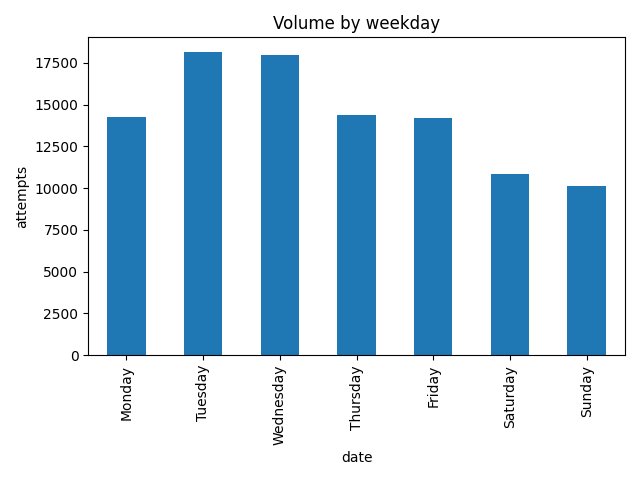

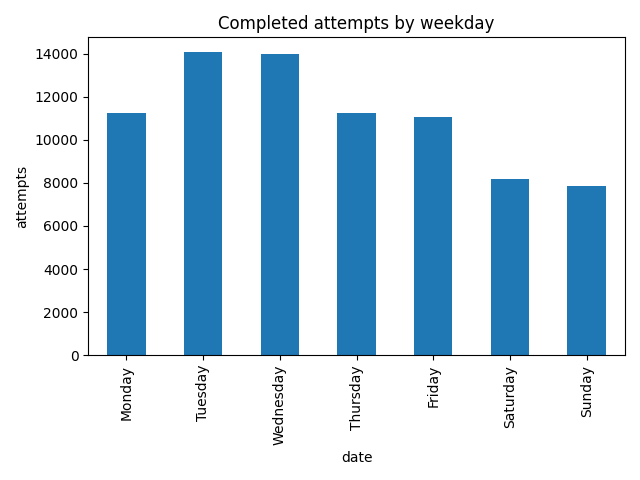

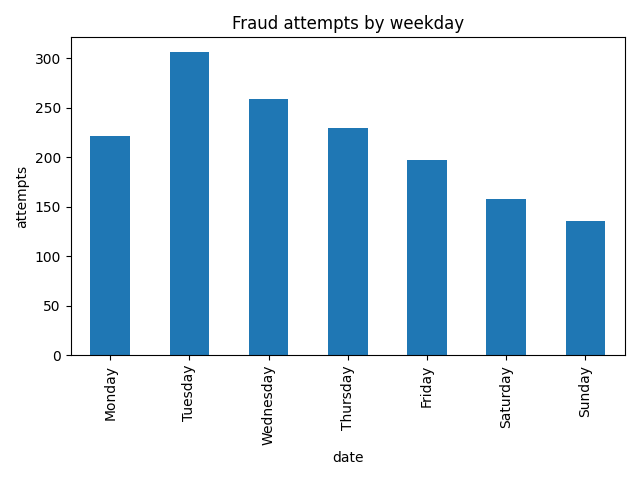

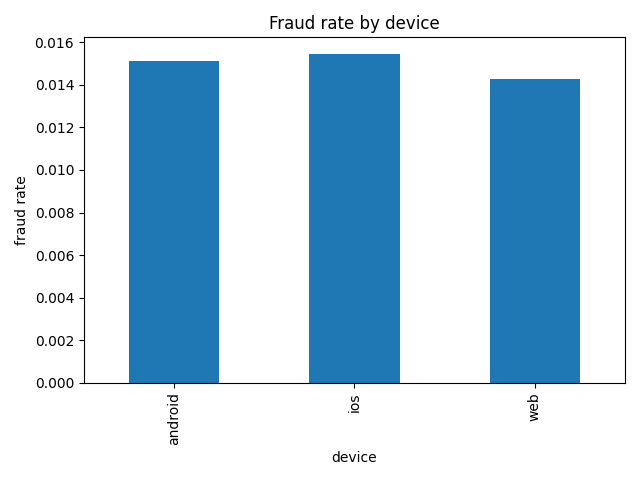

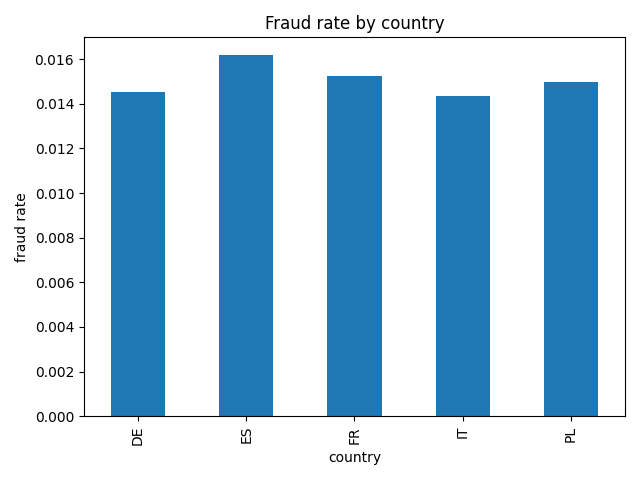

In [8]:
#perform EDA on the data
from IPython.display import Image, display

from config.paths import DATA_DIR
from sanity import eda_checks

eda_checks(df)
for name in (
    "eda_weekday.png",
    "eda_completed_weekday.png",
    "eda_fraud_weekday.png",
    "eda_fraud_device.png",
    "eda_fraud_country.png",
):
    display(Image(filename=str(DATA_DIR / name)))

#### EDA check conclusion 
The primary metric and all three guardrail metrics moved in the direction we pre-registered. Genuine completion is 79.6% in control versus 76.8% in treatment (−2.8 pp). Support contacts go from 4.1% to 5.6% (+1.5 pp), and median time among completers goes from 4.0 to 6.5 minutes. Every one of those gaps sits inside its threshold: the completion drop is under 5 pp, the support ratio is under 2, the time increase is under 3 minutes, and takeover blocked rate improved by more than 10 pp.

That is reassuring, but it is not a ship decision. These are raw point estimates with no uncertainty attached, and a 2.8 pp drop could have a confidence interval that reaches close to the 5 pp line. The hypothesis tests and the cost trade-off come next, and those are what decide this.

Attempt volume peaks Tuesday and Wednesday and is lowest on Saturday and Sunday. The weekend dip is expected, since we down-weighted weekend traffic in the simulator. Fraud prevalence is flat at roughly 1.4 to 1.6% across every device and country. The plots tell us fraud isn’t concentrated anywhere, but not whether control and treatment have the same device and country mix. That is checked in the next section with a chi-square balance test.

In [9]:
from sanity import sanity_checks

sanity = sanity_checks(df)
if not sanity["srm_passed"]:
    print(f"SRM failed (p={sanity['p_srm']:.4f}) - stopping analysis")
    sys.exit(1)
print(
    f"SRM passed (p={sanity['p_srm']:.4f}); "
    f"device balance p={sanity['p_device']:.4f}; "
    f"country balance p={sanity['p_country']:.4f}"
)

21:33:11 | INFO | sanity | Running sanity checks
variant
treatment    50229
control      49771
Name: count, dtype: int64
treatment share: 0.5023
SRM test results: chi2=2.098, p=0.1475

Device shares
device     android    ios    web
variant                         
control      0.451  0.349  0.201
treatment    0.449  0.351  0.200
Device balance test results: chi2=0.834, p=0.6589

Country shares
country       DE     ES     FR     IT     PL
variant                                     
control    0.196  0.121  0.348  0.080  0.254
treatment  0.200  0.119  0.354  0.078  0.248
Country balance test results: chi2=10.026, p=0.0400
SRM test passed: PASS
Device balance test passed: PASS
Country balance test passed: FAIL
SRM passed (p=0.1475); device balance p=0.6589; country balance p=0.0400


#### Sanity checks conclusion
Randomization looks good with one remark. The split is not exactly 50/50, but it is close (50.2% treatment, 49.8% control) and the SRM test passed with p= 0.148, which means there is no evidence of sample ratio mismatch. 

Device is balanced with p=0.659 but country balance fails with p=0.040. We consider this a minor imbalance rather than a broken assignment. No country differs by more than about 0.6 pp between control and treatment, and with 100k attempts even trivial differences can reach significance. It was also one of three balance checks, and p = 0.040 would not survive a Bonferroni correction (threshold around 0.017).

As a robustness check, I will re-estimate the treatment effects stratified by country.

In [10]:
#genuine completion by country, robustness check for country imbalance
g = df[df["is_fraud"] == 0]
rates = g.groupby(["country", "variant"])["completed"].mean().unstack()
rates["diff"] = rates["treatment"] - rates["control"]
rates.round(4)

variant,control,treatment,diff
country,,,
DE,0.8048,0.7641,-0.0407
ES,0.7969,0.7723,-0.0246
FR,0.7937,0.7675,-0.0261
IT,0.7922,0.7660,-0.0263
PL,0.7947,0.7703,-0.0244


#### Robustness check: genuine completion by country
Based on the results above, country is not a strong predictor of completion rate. In control, genuine completion ranges only from 79.2% (Italy) to 80.5% (Germany), so the small country imbalance has little room to bias the treatment effect.

The treatment effect is negative in every country, ranging from −2.4 pp (Poland) to −4.1 pp (Gerany). The country-level differences, weighted by country share, average to about −2.8 pp, in line with the pooled estimate. Germany shows a larger drop than the other four countries, about −4.1 percentage points against about −2.5 percentage points. It is still under the 5 percentage point threshold. These are point estimates without intervals, so I treat the larger German drop as something to check with a confidence interval, not as a separate finding.

Overall, the direction and size of the completion effect are consistent across countries, so the country balance flag does not change the conclusion.

### Statistical Analysis

In [11]:
#power analysis to check whether dataset has enough genuine attempts
from design import power_analysis

power_analysis(df)

Required n per variant (genuine): 6,507

21:33:11 | INFO | design | Running power analysis
Cohen's h: 0.0491
Daily genuine 3,283  ->  1,642/variant
Required days: 4.0 days | available days: 30 days
Required n per variant (genuine): 6,507 | current volume: 49,029
Status for 2% MDE: over-powered (have 49,029 / need 6,507)


#### Conclusion for power analysis

To detect a 2 pp difference in genuine completion (alphs = 0.05, 80% power) we need 6,507 genuine attempts per variant based on power analysis. Our dataset has 49,029 per variant, about 7.5 times more than necessary, so the test is overpowered for this effect size.

The downside of an overpowered test is that very small differences will be statistically significant. For this reason, our ship rule does not rely on p-values alone. It uses the CI of the primary metric and the guardrail metrics against the pre-registered thresholds, together with the cost analysis, so we focus on whether a change is large enough to matter and not only whether it is detectable.

In [12]:
#analysis of the primary metric - completion rate using z test, Wald CI and bootstrap CI
from effects import metrics_analysis
from config.settings import ALPHA

eff= metrics_analysis(df)
print("z stat completion rate",eff["z_stat_completion_rate"])
print("p value completion rate",eff["p_val_completion_rate"])
print("p value significant at alpha",ALPHA,eff["p_val_completion_rate"]<ALPHA)
print("CI completion rate","[",round(eff["ci_low_completion_rate"],4),",",round(eff["ci_high_completion_rate"],4),"]")
print("bootstrap CI for completion rate","[",round(eff["bootstrap_ci_low_completion_rate"],4),",",round(eff["bootstrap_ci_high_completion_rate"],4),"]")


21:33:11 | INFO | effects | Running metrics analysis
z stat completion rate -10.794586466264109
p value completion rate 3.65102408455535e-27
p value significant at alpha 0.05 True
CI completion rate [ -0.0335 , -0.0232 ]
bootstrap CI for completion rate [ -0.0336 , -0.0232 ]


#### Conclusion from statistical test for primary metric

The z-test shows that genuine completion rate is lower in treatment than in control (z = -10.79, p < 0.001), in the direction we pre-registered. The difference is statistically significant at alpha = 0.05.

In our dataset, we have about 100k attempts and even small drops are likely to be significant, so what matters most for the analysis is the size of the drop. The Wald 95% CI for the difference (treatment minus control) is -3.35 to -2.32 pp, which means that even the worst plausible drop is well inside the 5 pp guardrail.

As a robustness check, we also computed a bootstrap CI (-3.36 to -2.32 pp). It is aligned with the Wald CI to within 0.01 pp. The normal approximation holds and we can report Wald CI.

In [13]:
# primary metric: test for primary metric being concentrated not on 1 device
eff["device_results"]

,device,completion_rate_ctrl,completion_rate_treat,completion_rate_diff,p_value,p_value_fdr,significant
0,android,0.790243,0.766473,-0.023770,1.719242e-09,1.719242e-09,True
1,web,0.802132,0.761905,-0.040227,7.688316e-12,2.306495e-11,True
2,ios,0.801019,0.773389,-0.027629,3.765449e-10,5.648174e-10,True


#### Conclusion from statistical test for primary metric being concentrated not on 1 device

One of the ship rules is to check whether the completion drop is concentrated on a specific device. We ran a two-sample z-test on genuine completion separately for each device and adjusted the three p-values with Benjamini-Hochberg (FDR) to account for multiple testing.

Treatment completion is lower on every device: android −2.4 pp, ios −2.8 pp and web −4.0 pp. All three differences remain significant after FDR correction (adjusted p < 0.001), so the drop is not driven by a single device.

Web has the largest drop and is the closest to the 5 pp guardrail. These per-device tests show that the effect is present everywhere, not that it differs between devices, so we treat web as a point estimate to monitor rather than confirmed difference.

In [14]:
# first guardrail: takeover blocked among fraud, z-test and Wald CI (diff method)
print("z stat takeover blocked", eff["z_stat_takeover_blocked"])
print("p value takeover blocked", eff["p_val_takeover_blocked"])
print("p value significant at alpha", ALPHA, eff["p_val_takeover_blocked"] < ALPHA)
print("CI takeover blocked","[",round(eff["ci_low_takeover_blocked"], 4),",",round(eff["ci_high_takeover_blocked"], 4),"]",)

z stat takeover blocked 13.522321546510812
p value takeover blocked 1.154733578332675e-41
p value significant at alpha 0.05 True
CI takeover blocked [ 0.291 , 0.3828 ]


#### Conclusion from statistical test for 1st guardrail metric (takeover blocked among fraud)

The z-test shows that the takeover blocked rate is higher in treatment than in control (z = 13.52, p < 0.001), which is aligned with what we expected. The difference is statistically significant at alpha = 0.05.

Our ship rule requires the takeover blocked rate in treatment to be at least 10 pp higher than in control. The Wald 95% CI for the difference (treatment minus control) is +29.1 to +38.3 pp. The whole interval lies above 10 pp, so the guardrail is met with a large margin, even at the lower bound.

In [15]:
# second guardrail: support contact rate difference, z-test and Wald CI (ratio method)
print("z stat support contact", eff["z_stat_support_contact"])
print("p value support contact", eff["p_val_support_contact"])
print("p value significant at alpha", ALPHA, eff["p_val_support_contact"] < ALPHA)
print("support ratio", round(eff["support_ratio"],2))
print("CI support contact ratio","[",round(eff["ci_low_support_contact"], 4),",",round(eff["ci_high_support_contact"], 4),"]",)

z stat support contact 11.53471191118197
p value support contact 8.818188243625039e-31
p value significant at alpha 0.05 True
support ratio 1.38
CI support contact ratio [ 1.3101 , 1.4642 ]


#### Conclusion from statistical test for 2nd guardrail metric (support contact rate)

The z-test shows that the support contact rate is higher in treatment than in control (z = 11.53, p < 0.001), which is aligned with what we expected. The difference is statistically significant at alpha = 0.05.

Our ship rule requires the support contact ratio (treatment / control) to stay below 2. The observed ratio is 1.38, and the Wald 95% CI for the ratio is 1.31 to 1.46. The whole interval lies below 2, so the guardrail is met even at the upper bound.

In [16]:
# third guardrail: time to complete among completers; treat / ctrl >= 2.0 or (treat − ctrl) >= +3 min, mannwhitney and bootstrap CI
print("p value time median", eff["p_val_time_median"])
print("p value significant at alpha", ALPHA, eff["p_val_time_median"] < ALPHA)
print("time to complete (difference)", round(eff["time_lift"],2))
print("time to comlete (ratio)", round(eff["time_ratio"],2))
print("bootstrap CI time median difference","[",round(eff["bootstrap_ci_low_median_difference"], 4),",",round(eff["bootstrap_ci_high_median_difference"], 4),"]",)
print("bootstrap CI time median ratio","[",round(eff["bootstrap_ci_low_median_ratio"], 4),",",round(eff["bootstrap_ci_high_median_ratio"], 4),"]",)

p value time median 0.0
p value significant at alpha 0.05 True
time to complete (difference) 2.49
time to comlete (ratio) 1.62
bootstrap CI time median difference [ 2.43 , 2.54 ]
bootstrap CI time median ratio [ 1.6045 , 1.6357 ]


#### Conclusion from statistical test for 3rd guardrail metric (time to complete among completers)

Since time to complete is right-skewed, we used the Mann-Whitney U test (two-sided). It shows that the distributions of time to complete differ between treatment and control (p < 0.001), and the medians show that treatment is slower, which is aligned with what we expected. The difference is statistically significant at alpha = 0.05.

Our ship rule requires two things: the ratio of median time to complete (treatment / control) must stay below 2, and the difference in median time must be less than 3 min.

The observed difference in medians is 2.49 min, and the bootstrap 95% CI is 2.43 to 2.54 min. The whole interval lies below 3 min, so this condition is met even at the upper bound. The observed ratio is 1.62, and the bootstrap 95% CI is 1.60 to 1.64. The whole interval lies below 2, so this condition is also met even at the upper bound.

In [17]:
# cost tradeoff: net value per 100k attempts at the locked costs, and the sensitivity grid
from tradeoff import run_tradeoff

trade = run_tradeoff(
    df,
    eff["ctrl_completion_rate"],
    eff["treat_completion_rate"],
    eff["ctrl_takeover_blocked_rate"],
    eff["treat_takeover_blocked_rate"],
)

21:33:21 | INFO | tradeoff | Running cost sensitivity analysis
Lost genuine / 100k: 2797
Takeovers prevented / 100k: 508
Cost lost genuine (assumption): 60 EUR
Cost takeover (assumption): 400 EUR
Benefit: 203,220 EUR | Cost: 167,816 EUR | Net: 35,403 EUR
Break-even ratio cost_takeover/cost_lost = 5.51

Net EUR / 100k (positive => value supports ship)
         takeover=100  takeover=250  takeover=400  takeover=750  takeover=1000
lost=10         22836         99043        175250        353067         480080
lost=20         -5134         71074        147281        325098         452110
lost=30        -33103         43104        119311        297129         424141
lost=50        -89042        -12835         63373        241190         368202
lost=80       -172950        -96743        -20535        157282         284294


#### Conclusion from the cost trade-off

The cost analysis checks whether the money saved by blocking more takeovers outweighs the money lost from genuine users who fail to complete. It uses the locked assumptions from [`docs/cost_assumptions.md`](../docs/cost_assumptions.md): 60 EUR per lost genuine completion and 400 EUR per successful account takeover. Under these costs, treatment has a net benefit of 35,403 EUR per 100k attempts, which satisfies the ship rule (net > 0).

We also ran a sensitivity grid with other combinations of the two costs. The break-even ratio is 5.51: treatment pays off only if one takeover costs at least 5.5 times as much as one lost genuine completion. Our assumed ratio is 6.7 (400 / 60), so we are above break-even.

For example, if a lost genuine completion costs 20 EUR and a takeover only 100 EUR (ratio 5.0), the net is −5,134 EUR per 100k attempts, so it would not be worth shipping the new verification feature. The result therefore depends on the cost assumptions and not on the statistics: if finance believes a lost genuine user is worth much more, or a takeover much less than assumed, the conclusion could flip.

21:33:21 | INFO | anomaly | Running anomaly detection
Investigating planted anomaly android/2026-09-12 (1177 genuine rows flagged)

WITH anomaly rows: diff=-0.0284 95% CI [-0.0335, -0.0232] ctrl=0.7964 treat=0.7680

WITHOUT anomaly rows: diff=-0.0288 95% CI [-0.0340, -0.0236] ctrl=0.7994 treat=0.7706

2026-09-12 by device x variant:

android completion by variant (anomaly day vs other days):
anomaly day:             mean  count
variant                
control    0.565    628
treatment  0.537    549
other days:             mean  count
variant                
control    0.797  21469
treatment  0.772  21654


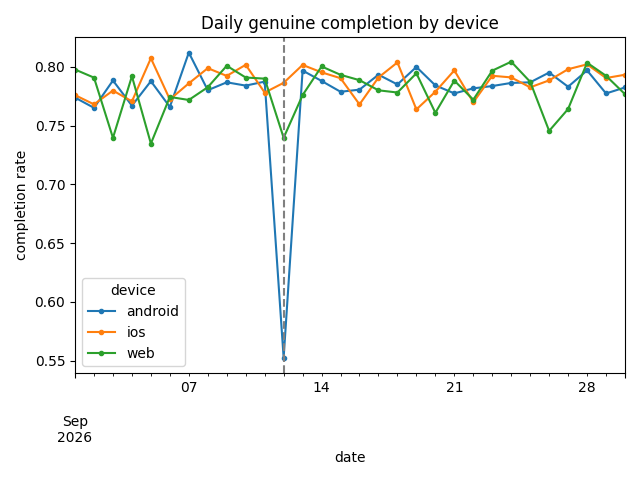

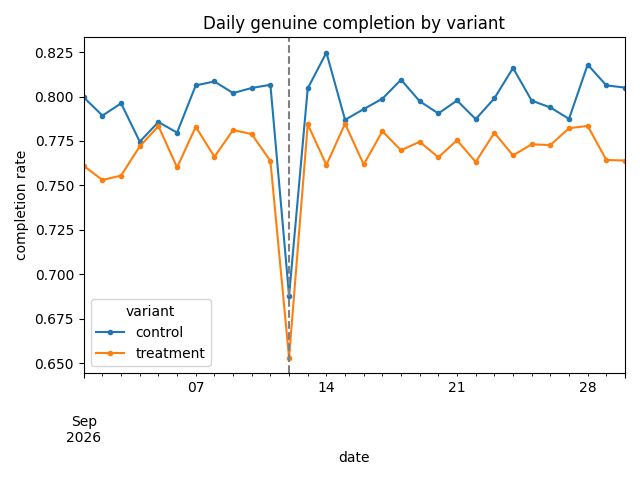

In [18]:
# anomaly RCA
from anomaly import run_anomaly
from config.paths import FIG_PATH

anom = run_anomaly(df, FIG_PATH)

for name in (
    "kpi_by_device.png",
    "kpi_by_variant.png",
):
    display(Image(filename=str(DATA_DIR / name)))

#### Conclusion for anomaly analysis

The simulated data contains one planted anomaly: on 2026-09-12 genuine completion on Android drops to about 56% (control 56.5%, treatment 53.7%), compared with about 78% on other days (the setting is locked in [`config/settings.py`](../config/settings.py)). The daily plot by device shows the dip clearly, and it appears only on Android. The anomaly flags 1,177 genuine rows (628 control, 549 treatment).

To see whether it affects the result, we computed the Wald 95% CI for the completion difference with and without the anomaly rows. With the anomaly the difference is −2.84 pp (95% CI −3.35 to −2.32) and without it, −2.88 pp (95% CI −3.40 to −2.36). The two intervals are almost the same, so the anomaly does not change our conclusion.

#### Final decision

* **Ship checks: all pass, including at the worst end of each 95% CI.**
  * Genuine completion drop is −2.8 pp (CI −3.35 to −2.32), under the 5 pp limit.
  * Takeover-blocked lift is about +33.7 pp (CI +29.1 to +38.3), above the 10 pp minimum.
  * Support contact ratio is 1.38 (CI 1.31 to 1.46), under 2.
  * Time to complete: the ratio is 1.62 (CI 1.60 to 1.64), under 2, and the median lift is 2.49 min (CI 2.43 to 2.54), under 3 min.
  * Net value at 60 EUR / 400 EUR is +35,403 EUR per 100k attempts, above 0.

* **The call: ship.** The new verification step meets every pre-registered ship rule, and the extra takeovers it blocks outweigh the genuine completions it costs at the agreed cost assumptions.